# Laboratorio 10: Búsqueda por Similitud

Dataset: **Dry Bean** (UCI id=602), 13 611 granos con 16 atributos numéricos y 7 clases.

## Carga de Datos

In [35]:
import os
import pandas as pd

DATA_PATH = "data/dry_bean.csv"

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    from ucimlrepo import fetch_ucirepo
    dry_bean = fetch_ucirepo(id=602)
    X = dry_bean.data.features
    y = dry_bean.data.targets
    df = pd.concat([X, y], axis=1)
    os.makedirs("data", exist_ok=True)
    df.to_csv(DATA_PATH, index=False)

FEATURES = list(df.columns[:16])
TARGET = df.columns[16]

print(f"Filas: {len(df)}, atributos: {len(FEATURES)}, clases: {df[TARGET].nunique()}")
df.head()

Filas: 13611, atributos: 16, clases: 7


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## Tratamiento de Datos

Cada grano se representa con un vector de características $x \in \mathbb{R}^{16}$: toda consulta trabaja solo con esta abstracción y no con la imagen original. La similitud se mide con la distancia euclidiana:

$$d(x, y) = \sqrt{\sum_{i=1}^{D} |x_i - y_i|^2}$$

La distancia euclidiana considera magnitud, escala y diferencias absolutas. Si un atributo tiene valores mucho más grandes que los demás, domina la distancia y el resto deja de influir. Antes de buscar hay que revisar:

1. Calidad de los datos: tipos, valores nulos y duplicados.
2. Escala de cada atributo y su aporte a la distancia.
3. Normalización para que los 16 atributos aporten por igual.

### 1. Calidad de los datos

In [36]:
print("Tipos de datos:")
print(df[FEATURES].dtypes.value_counts().to_string())
print(f"\nValores nulos: {df.isna().sum().sum()}")
print(f"Filas duplicadas (mismo vector y clase): {df.duplicated().sum()}")
print("\nGranos por clase:")
print(df[TARGET].value_counts().to_string())

Tipos de datos:
float64    14
int64       2

Valores nulos: 0
Filas duplicadas (mismo vector y clase): 68

Granos por clase:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522


- Los 16 atributos son numéricos y no hay nulos, así que no se necesita imputación.
- Las filas duplicadas **no se eliminan**: borrarlas cambiaría los índices y `Q15`, `Q2166` y `Q4768` ya no serían los mismos objetos (ni coincidirían con los `id` de PostgreSQL en P3). En las búsquedas aparecerán a distancia 0 de su copia, lo cual es correcto.
- Las clases están desbalanceadas (DERMASON ≈ 26 %, BOMBAY ≈ 4 %). Esto influye en la precisión: con radios grandes la precisión tiende a la proporción de la clase de la consulta.

### 2. Escala de los atributos

Para dos objetos aleatorios $x, y$ se cumple $E[(x_i - y_i)^2] = 2\,\mathrm{Var}(x_i)$, por lo que el aporte de cada atributo a la distancia euclidiana al cuadrado es proporcional a su varianza.

In [37]:
import numpy as np

X_raw = df[FEATURES].to_numpy(dtype=float)
y = df[TARGET].to_numpy()

var_raw = X_raw.var(axis=0)
escala = pd.DataFrame({
    "min": X_raw.min(axis=0),
    "max": X_raw.max(axis=0),
    "desv. estándar": X_raw.std(axis=0),
    "aporte a d² (%)": var_raw / var_raw.sum() * 100,
}, index=FEATURES).sort_values("aporte a d² (%)", ascending=False)

escala.style.format({"min": "{:.4f}", "max": "{:.4f}", "desv. estándar": "{:.4f}", "aporte a d² (%)": "{:.4f}"})

,min,max,desv. estándar,aporte a d² (%)
ConvexArea,20684.0000,263261.0000,29773.8220,50.7611
Area,20420.0000,254616.0000,29323.0185,49.2356
Perimeter,524.7360,1985.3700,214.2818,0.0026
MajorAxisLength,183.6012,738.8602,85.6910,0.0004
EquivDiameter,161.2438,569.3744,59.1749,0.0002
MinorAxisLength,122.5127,460.1985,44.9684,0.0001
AspectRatio,1.0249,2.4303,0.2467,0.0000
ShapeFactor3,0.4103,0.9748,0.0990,0.0000
Eccentricity,0.2190,0.9114,0.0920,0.0000
Compactness,0.6406,0.9873,0.0617,0.0000


Sin normalizar, `ConvexArea` y `Area` (valores del orden de $10^4$–$10^5$) concentran casi el 100 % de la distancia, mientras que atributos como `roundness`, `Solidity` o los `ShapeFactor` (valores entre 0 y 1) no aportan nada. La búsqueda solo compararía el tamaño del grano e ignoraría su forma, que es lo que distingue a varias clases.

### 3. Normalización z-score

Se estandariza cada atributo con su media y desviación estándar:

$$x'_i = \frac{x_i - \mu_i}{\sigma_i}$$

Así cada atributo queda con media 0 y desviación 1, y todos aportan lo mismo a la distancia (1/16 = 6.25 %). Se prefiere z-score sobre min-max porque es menos sensible a valores extremos: min-max depende solo del mínimo y del máximo de cada atributo.

In [38]:
mu = X_raw.mean(axis=0)
sigma = X_raw.std(axis=0)
X = (X_raw - mu) / sigma

var_norm = X.var(axis=0)
pd.DataFrame({
    "media": X.mean(axis=0),
    "desv. estándar": X.std(axis=0),
    "aporte a d² (%)": var_norm / var_norm.sum() * 100,
}, index=FEATURES).round(4)

,media,desv. estándar,aporte a d² (%)
Area,0.0,1.0,6.25
Perimeter,-0.0,1.0,6.25
MajorAxisLength,0.0,1.0,6.25
MinorAxisLength,0.0,1.0,6.25
AspectRatio,-0.0,1.0,6.25
Eccentricity,-0.0,1.0,6.25
ConvexArea,0.0,1.0,6.25
EquivDiameter,0.0,1.0,6.25
Extent,0.0,1.0,6.25
Solidity,0.0,1.0,6.25


### Objetos de consulta

Las consultas se identifican por su `id` (1-based), la misma convención que en `dry_beans` (P3): la fila `i` del DataFrame corresponde a `id = i + 1`, así que $Q_{15}$ es la fila 14.

In [39]:
QUERY_IDS = [15, 2166, 4768]
QUERY_ROWS = {qid: qid - 1 for qid in QUERY_IDS}

pd.DataFrame({
    "id": QUERY_IDS,
    "fila": [QUERY_ROWS[q] for q in QUERY_IDS],
    "clase": [y[QUERY_ROWS[q]] for q in QUERY_IDS],
})

,id,fila,clase
0,15,14,SEKER
1,2166,2165,BARBUNYA
2,4768,4767,CALI


## P1a

### a) Análisis de la distribución de la distancia

El problema de la consulta por rango es elegir el radio de tolerancia $r$: si es muy pequeño no retorna nada y si es muy grande retorna demasiado. Para elegirlo con criterio se estima la distribución de distancias de la colección calculando la distancia euclidiana entre **5000 pares de objetos aleatorios** (sobre los vectores normalizados).

In [40]:
import matplotlib.pyplot as plt


def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))


N_PAIRS = 5000
rng = np.random.default_rng(42)

pairs = []
while len(pairs) < N_PAIRS:
    i, j = rng.integers(0, len(X), size=2)
    if i != j:
        pairs.append((i, j))

dists = np.array([euclidean(X[i], X[j]) for i, j in pairs])
pd.Series(dists, name="distancia").describe(percentiles=[.01, .02, .05, .10, .20, .50, .90]).round(3)

count    5000.000
mean        5.018
std         2.703
min         0.352
1%          0.958
2%          1.174
5%          1.556
10%         2.023
20%         2.734
50%         4.578
90%         8.559
max        20.530
Name: distancia, dtype: float64

Los radios se toman de **percentiles bajos** de la distribución: el percentil $p$ indica que un $p\,\%$ de los pares aleatorios están a esa distancia o menos, así que un radio en el percentil 1 cubre aproximadamente al 1 % de la colección. Percentiles altos (p. ej. la mediana) cubrirían a la mitad de la colección y la búsqueda dejaría de ser selectiva.

In [41]:
PERCENTILES = [1, 2, 5, 10, 20]
RADII = np.percentile(dists, PERCENTILES)

pd.DataFrame({
    "radio": [f"r{k}" for k in range(1, 6)],
    "percentil": PERCENTILES,
    "valor": RADII.round(4),
})

,radio,percentil,valor
0,r1,1,0.9577
1,r2,2,1.1743
2,r3,5,1.5561
3,r4,10,2.0234
4,r5,20,2.7337


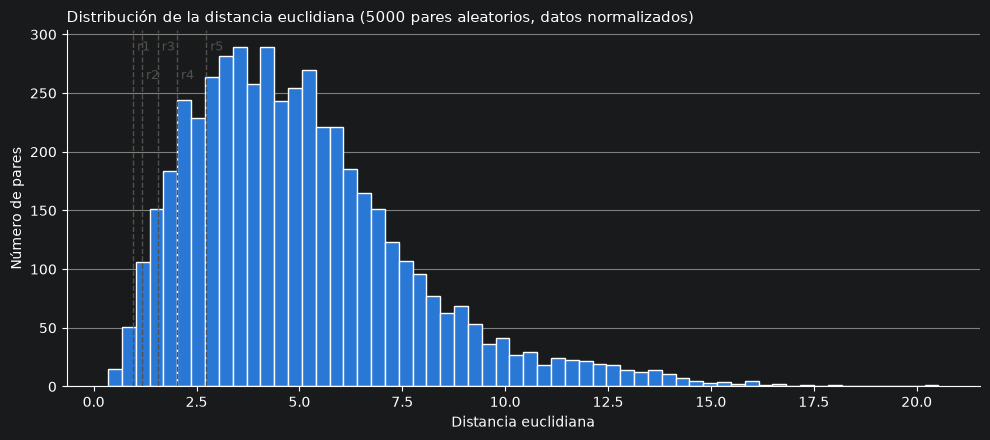

In [42]:
os.makedirs("results", exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(dists, bins=60, color="#2a78d6", edgecolor="#fcfcfb", linewidth=1)
for k, r in enumerate(RADII, start=1):
    ax.axvline(r, color="#52514e", linestyle="--", linewidth=1)
    ax.text(r, ax.get_ylim()[1] * (0.97 if k % 2 else 0.89), f" r{k}", color="#52514e", fontsize=9, va="top")

ax.set_title(f"Distribución de la distancia euclidiana ({N_PAIRS} pares aleatorios, datos normalizados)",
             loc="left", fontsize=11)
ax.set_xlabel("Distancia euclidiana")
ax.set_ylabel("Número de pares")
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

fig.tight_layout()
fig.savefig("results/p1_distribucion.png", dpi=150)
plt.show()

## P1b

### b) Algoritmo de Búsqueda por Rango

Dado un objeto de consulta $q$ y un radio de tolerancia $r \in \mathbb{R}^+$, la consulta por rango retorna todos los objetos de la colección dentro de la **bola de consulta**:

$$(q, r) = \{u \in \mathbb{U} : \delta(u, q) \le r\}$$

El algoritmo lineal recorre toda la colección, calcula $\delta(u, q)$ con la distancia euclidiana y conserva los objetos con $\delta(u, q) \le r$. El objeto de consulta se retira de la colección antes de buscar (si no, siempre aparecería a distancia 0). El costo es $O(n \cdot D)$: una distancia de costo $O(D)$ por cada uno de los $n$ objetos.

La efectividad se mide con la **precisión**: de los objetos recuperados, cuántos pertenecen a la misma clase que la consulta.

$$PR = \frac{\#ObjetosRelevantesRecuperados}{\#ObjetosRecuperados} = \frac{TP}{TP + FP}$$

In [43]:
def range_search(X, q_row, r):
    q = X[q_row]
    result = []
    for i in range(len(X)):
        if i == q_row:  
            continue
        d = euclidean(X[i], q)
        if d <= r:
            result.append((i, d))
    result.sort(key=lambda t: t[1])
    return result


def precision(result, q_class):
    if not result:
        return float("nan")
    relevantes = sum(1 for i, _ in result if y[i] == q_class)
    return relevantes / len(result)

In [44]:
pr_table = pd.DataFrame(index=[f"r{k} = {r:.4f}" for k, r in enumerate(RADII, start=1)],
                        columns=[f"Q{q}" for q in QUERY_IDS], dtype=float)
n_table = pr_table.copy()

for qid in QUERY_IDS:
    q_row = QUERY_ROWS[qid]
    for k, r in enumerate(RADII):
        result = range_search(X, q_row, r)
        pr_table.iloc[k, QUERY_IDS.index(qid)] = precision(result, y[q_row])
        n_table.iloc[k, QUERY_IDS.index(qid)] = len(result)

pr_table.to_csv("results/p1_precision.csv")
n_table.astype(int).to_csv("results/p1_recuperados.csv")

print("Precisión (PR):")
display(pr_table.round(4))
print("Objetos recuperados:")
display(n_table.astype(int))

Precisión (PR):


,Q15,Q2166,Q4768
r1 = 0.9577,1.0000,1.0000,1.0000
r2 = 1.1743,1.0000,1.0000,1.0000
r3 = 1.5561,0.9969,0.9327,0.9896
r4 = 2.0234,0.9909,0.7851,0.9055
r5 = 2.7337,0.9834,0.4051,0.7228


Objetos recuperados:


,Q15,Q2166,Q4768
r1 = 0.9577,89,5,13
r2 = 1.1743,156,22,25
r3 = 1.5561,321,104,96
r4 = 2.0234,660,335,307
r5 = 2.7337,1208,1671,1093


Ejemplo: los 10 objetos más cercanos recuperados para $Q_{15}$ con el radio $r_1$.

In [45]:
q_row = QUERY_ROWS[15]
ejemplo = range_search(X, q_row, RADII[0])[:10]
pd.DataFrame({
    "id": [i + 1 for i, _ in ejemplo],
    "distancia": [round(d, 4) for _, d in ejemplo],
    "clase": [y[i] for i, _ in ejemplo],
    "relevante": [y[i] == y[q_row] for i, _ in ejemplo],
})

,id,distancia,clase,relevante
0,19,0.2903,SEKER,True
1,41,0.3778,SEKER,True
2,122,0.4576,SEKER,True
3,31,0.4698,SEKER,True
4,93,0.4833,SEKER,True
5,16,0.4899,SEKER,True
6,54,0.4950,SEKER,True
7,12,0.5225,SEKER,True
8,184,0.5776,SEKER,True
9,150,0.5776,SEKER,True


### Análisis de resultados

| PR | $Q_{15}$ (SEKER) | $Q_{2166}$ (BARBUNYA) | $Q_{4768}$ (CALI) |
|---|---|---|---|
| r1 = 0.9577 | 1.0000 (89) | 1.0000 (5) | 1.0000 (13) |
| r2 = 1.1743 | 1.0000 (156) | 1.0000 (22) | 1.0000 (25) |
| r3 = 1.5561 | 0.9969 (321) | 0.9327 (104) | 0.9896 (96) |
| r4 = 2.0234 | 0.9909 (660) | 0.7851 (335) | 0.9055 (307) |
| r5 = 2.7337 | 0.9834 (1208) | 0.4051 (1671) | 0.7228 (1093) |

*Entre paréntesis: número de objetos recuperados.*

- **La precisión baja al aumentar el radio.** Con radios pequeños solo entran vecinos muy parecidos y la precisión es 1.0; al crecer la bola de consulta se recuperan más objetos relevantes pero también objetos de otras clases. Es la relación empírica precisión vs. exhaustividad: ganar *recall* cuesta precisión.
- **El número de resultados no se controla.** Con el mismo radio $r_1$, $Q_{15}$ recupera 89 objetos y $Q_{2166}$ solo 5. Es el problema de elegir el radio: un mismo $r$ es "grande" en una zona densa del espacio y "pequeño" en una zona dispersa.
- **$Q_{15}$ (SEKER)** está en una región densa y bien separada: con $r_5$ recupera 1208 objetos con 98 % de precisión (solo 20 DERMASON se cuelan).
- **$Q_{2166}$ (BARBUNYA)** está cerca de la frontera con otras clases: con $r_5$ recupera 677 BARBUNYA pero también 462 SIRA, 315 CALI y 214 HOROZ, y su precisión cae a 0.41.
- **$Q_{4768}$ (CALI)** queda en un punto intermedio: su principal confusión es con HOROZ (228 objetos con $r_5$).
- **Sin normalizar**, la distancia dependería casi solo de `Area` y `ConvexArea` (ver *Tratamiento de Datos*), por lo que la búsqueda compararía solo el tamaño del grano y no su forma.

## P2

El algoritmo KNN recibe un objeto de consulta $q$ y un número entero $k \ge 1$. Retorna los $k$ objetos más cercanos de la colección ordenados por distancia euclidiana.

A diferencia de la búsqueda por rango, KNN asegura devolver exactamente $k$ resultados, independientemente de la densidad de la zona.

Para implementar el algoritmo de forma eficiente, se gestionan los candidatos en un max heap de tamaño $k$)usando la librería `heapq` de Python:
- Mantiene las distancias como números negativos para simular un max heap.
- Si el heap tiene menos de $k$ elementos, se inserta directamente $O(\log k)$.
- Si la distancia al objeto actual es menor que la distancia del elemento más lejano del heap (la raíz `-heap[0][0]`), se reemplaza en $O(\log k)$.

In [46]:
import heapq

def knn_search(X, q_row, k):
    q = X[q_row]
    max_heap = []  

    for i in range(len(X)):
        if i == q_row:  
            continue
        
        d = euclidean(X[i], q)

        if len(max_heap) < k:
            heapq.heappush(max_heap, (-d, i))
        else:
            # Si la distancia actual es menor que la peor del top-k
            if d < -max_heap[0][0]:
                heapq.heappushpop(max_heap, (-d, i))

    # Extraer los k vecinos y ordenarlos de menor a mayor distancia
    res = [(-d, i) for d, i in max_heap]
    res.sort(key=lambda t: t[0])
    return [(i, d) for d, i in res]


def precision_knn(result, q_class):
    if not result:
        return 0.0
    relevantes = sum(1 for i, _ in result if y[i] == q_class)
    return relevantes / len(result)

k_vals = [2, 4, 8, 16, 32]

knn_pr_table = pd.DataFrame(
    index=[f"k = {k}" for k in k_vals],
    columns=[f"Q{q}" for q in QUERY_IDS],
    dtype=float
)

for qid in QUERY_IDS:
    q_row = QUERY_ROWS[qid]
    q_class = y[q_row]
    
    for k in k_vals:
        result = knn_search(X, q_row, k)
        pr = precision_knn(result, q_class)
        knn_pr_table.loc[f"k = {k}", f"Q{qid}"] = pr

knn_pr_table.to_csv("results/p2_precision_knn.csv")

print("Tabla de Precisión para KNN:")
display(knn_pr_table.round(4))

Tabla de Precisión para KNN:


,Q15,Q2166,Q4768
k = 2,1.0,1.0,1.0
k = 4,1.0,1.0,1.0
k = 8,1.0,1.0,1.0
k = 16,1.0,1.0,1.0
k = 32,1.0,1.0,1.0


### Preguntas de Análisis: Rango vs. KNN

**¿Cuál de los dos métodos de búsqueda usted usaría en un ambiente real de recuperación de la información?**

En un ambiente real de producción/recuperación de información, utilizaríamos KNN por las siguientes razones:

1. Predicibilidad y control en la respuesta: KNN asegrua devolver un tamaño de resultado constante ($k$), lo que facilita la paginación y evita saturar la memoria o la red. En la búsqueda por rango, si se elige un radio $r$ muy grande, se pueden retornar miles de objetos innecesarios; y si $r$ es muy pequeño, se puede retornar la lista vacía.
2. Independencia de la densidad local: En datasets reales, la densidad de puntos varía según la región del espacio vectorial. Calibrar un radio global $r$ para la búsqueda por rango es muy difícil. KNN se adapta automáticamente a la densidad local en torno a la consulta.
3. Puntuación y Ranking: KNN entrega de forma nativa los $k$ mejores candidatos ordenados por relevancia/similitud para ser presentados directamente al usuario.

## P3: KNN en PostgreSQL

### Carga en PostgreSQL

```sql
CREATE EXTENSION IF NOT EXISTS cube;

CREATE TABLE dry_beans (
    id SERIAL PRIMARY KEY,
    features_seq cube,
    features_idx cube
);

CREATE INDEX dry_beans_features_idx_gist ON dry_beans USING gist (features_idx);
```

> La extensión, la tabla y el índice se crean al hacer `docker compose up` (ver `init.sql`).

Se cargan los vectores **normalizados** (`X`, z-score) para que las distancias en PostgreSQL sean las mismas que en P1 y P2. La fila `i` del DataFrame (0-based) corresponde a `id = i + 1` en `dry_beans`. Para recargar desde cero: `docker compose down -v`.

In [47]:
import psycopg2
from psycopg2.extras import execute_values


def connect_db():
    return psycopg2.connect(
        dbname="labsimilarity", user="postgres",
        password="postgres", host="localhost", port=5434,
        options="-c max_parallel_workers_per_gather=0",
    )


conn = connect_db()
with conn.cursor() as cur:
    cur.execute("SELECT COUNT(*) FROM dry_beans;")
    if cur.fetchone()[0] == 0:
        execute_values(cur,
                       "INSERT INTO dry_beans (features_seq, features_idx) VALUES %s;",
                       [(vec, vec) for vec in X.tolist()],
                       template="(cube(%s::float8[]), cube(%s::float8[]))", page_size=1000)
        conn.commit()
    cur.execute("SELECT COUNT(*) FROM dry_beans;")
    print(f"Filas en dry_beans: {cur.fetchone()[0]}")
conn.close()

Filas en dry_beans: 13611


### KNN secuencial vs. GiST

Planes para $Q_{15}$ con $k = 8$:

In [48]:
def knn_sql(column, table="dry_beans", fmt="TEXT"):
    return f"""EXPLAIN (ANALYZE, BUFFERS, FORMAT {fmt})
               SELECT id, {column},
               {column} <-> cube(%s::float8[]) AS distancia
               FROM {table}
               ORDER BY distancia
               LIMIT %s;"""


conn = connect_db()
with conn.cursor() as cur:
    for column in ("features_seq", "features_idx"):
        cur.execute(knn_sql(column), (X[QUERY_ROWS[15]].tolist(), 8))
        print(f"Plan para {column}")
        print("\n".join(row[0] for row in cur.fetchall()), "\n")
conn.close()

Plan para features_seq
Limit  (cost=966.36..966.38 rows=8 width=148) (actual time=5.937..5.941 rows=8 loops=1)
  Buffers: shared hit=3 read=524
  ->  Sort  (cost=966.36..1000.39 rows=13611 width=148) (actual time=5.935..5.937 rows=8 loops=1)
        Sort Key: ((features_seq <-> '(-0.7465222097347709, -0.999517620229169, -1.2612158146151888, -0.3352963594400207, -1.825775638813909, -3.0540837980562228, -0.7487852985103114, -0.9106373736023344, 0.6433934278372714, 0.6045059477939979, 1.3330701247904169, 2.2581830379575827, 0.21505477461882033, 2.6030963296524425, 2.4096961838612616, 0.981514962058878)'::cube))
        Sort Method: top-N heapsort  Memory: 29kB
        Buffers: shared hit=3 read=524
        ->  Seq Scan on dry_beans  (cost=0.00..694.14 rows=13611 width=148) (actual time=0.015..4.398 rows=13611 loops=1)
              Buffers: shared read=524
Planning:
  Buffers: shared hit=121 read=2
Planning Time: 0.943 ms
Execution Time: 6.007 ms 

Plan para features_idx
Limit  (cost=0.28

La búsqueda secuencial lee las 13 611 filas (`Seq Scan`), calcula todas las distancias y conserva las $k$ menores con `top-N heapsort`. La indexada recorre el R-Tree en orden de distancia (`Index Scan ... Order By <->`): extrae solo $k$ filas, ya ordenadas, por lo que no necesita un nodo `Sort`.

Cada combinación (objeto de consulta, $k$, columna) se ejecuta `N_REPS` veces y se reporta la mediana del `Execution Time` de `EXPLAIN ANALYZE` en ms. Las repeticiones se hacen por rondas (en cada ronda se ejecutan todas las combinaciones una vez), así una perturbación temporal, como caché fría o carga del sistema, se reparte entre todas las combinaciones en lugar de concentrarse en las primeras. Se usa la mediana porque los tiempos solo tienen valores atípicos hacia arriba, y estos alteran la media pero no la mediana.

In [49]:
K_VALUES = [2, 4, 8, 16, 32]
COLUMNS = {"features_seq": "Secuencial", "features_idx": "GiST"}
N_REPS = 20


def knn_plan(cur, column, q, k, table="dry_beans"):
    cur.execute(knn_sql(column, table, fmt="JSON"), (q, k))
    return cur.fetchone()[0][0]


def knn_time(cur, column, q, k, table="dry_beans"):
    return knn_plan(cur, column, q, k, table)["Execution Time"]


rows = []
conn = connect_db()
with conn.cursor() as cur:
    for _ in range(N_REPS):
        for qid in QUERY_IDS:
            q = X[QUERY_ROWS[qid]].tolist()
            for k in K_VALUES:
                for column, metodo in COLUMNS.items():
                    rows.append({"consulta": f"Q{qid}", "k": k, "método": metodo, "ms": knn_time(cur, column, q, k)})
conn.close()

knn_times = pd.DataFrame(rows).groupby(["consulta", "k", "método"], as_index=False)["ms"].median()
knn_times.to_csv("results/p3_knn_tiempos.csv", index=False)

tabla = knn_times.pivot_table(index="k", columns=["consulta", "método"], values="ms")
tabla = tabla.reindex(columns=pd.MultiIndex.from_product([[f"Q{q}" for q in QUERY_IDS], COLUMNS.values()]))
speedup = tabla.xs("Secuencial", axis=1, level=1) / tabla.xs("GiST", axis=1, level=1)

print("Tiempo de ejecución (ms):")
display(tabla.round(3))
print("Speedup (Secuencial / GiST):")
display(speedup.round(1))

Tiempo de ejecución (ms):


Q15             Q2166             Q4768       
   Secuencial   GiST Secuencial   GiST Secuencial   GiST
k                                                       
2       2.731  0.054      2.730  0.264      2.698  0.129
4       2.714  0.068      2.702  0.366      2.698  0.179
8       2.718  0.074      2.738  0.397      2.734  0.186
16      2.718  0.096      2.739  0.436      2.705  0.238
32      2.750  0.130      2.746  0.570      2.770  0.347

Speedup (Secuencial / GiST):


,Q15,Q2166,Q4768
k,,,
2,51.0,10.4,20.9
4,40.2,7.4,15.1
8,37.0,6.9,14.7
16,28.2,6.3,11.3
32,21.1,4.8,8.0


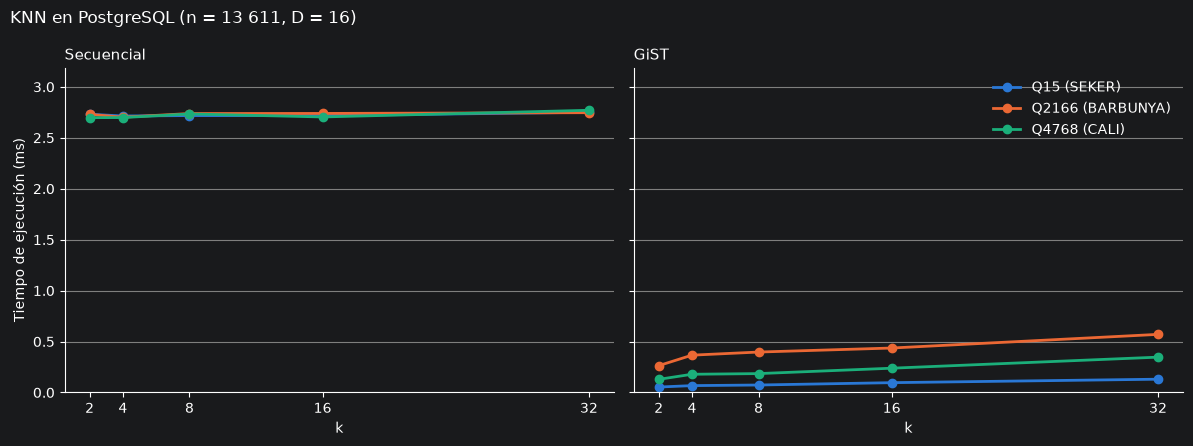

In [50]:
COLORS = dict(zip([f"Q{q}" for q in QUERY_IDS], ["#2a78d6", "#eb6834", "#1baf7a"]))


def plot_tiempos(tabla, xlabel, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, metodo in zip(axes, COLUMNS.values()):
        for consulta, color in COLORS.items():
            label = f"{consulta} ({y[QUERY_ROWS[int(consulta[1:])]]})"
            ax.plot(tabla.index, tabla[(consulta, metodo)], color=color, linewidth=2, marker="o", markersize=6, label=label)
        ax.set_title(metodo, loc="left", fontsize=11)
        ax.set_xticks(tabla.index, [f"{v:,}".replace(",", " ") for v in tabla.index])
        ax.set_xlabel(xlabel)
        ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)

    axes[0].set_ylim(0, tabla.max().max() * 1.15)
    axes[0].set_ylabel("Tiempo de ejecución (ms)")
    axes[1].legend(frameon=False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)

    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


plot_tiempos(tabla, "k", "KNN en PostgreSQL (n = 13 611, D = 16)", "results/p3_knn_tiempos.png")

### Escalabilidad

Se replica la colección en una tabla aparte, `dry_beans_rep`, con `INSERT INTO ... SELECT ... FROM`. Cada réplica duplica la tabla: 13 611 → 27 222 → 54 444 filas. En cada tamaño se mide KNN con $k = 8$ en ambas columnas, igual que antes.

In [51]:
REP_K = 8
REPLICAS = 2

rows = []
conn = connect_db()
conn.autocommit = True
with conn.cursor() as cur:
    cur.execute("""
        DROP TABLE IF EXISTS dry_beans_rep;
        CREATE TABLE dry_beans_rep (id SERIAL PRIMARY KEY, features_seq cube, features_idx cube);
        CREATE INDEX ON dry_beans_rep USING gist (features_idx);
        INSERT INTO dry_beans_rep (features_seq, features_idx) SELECT features_seq, features_idx FROM dry_beans;
    """)
    for rep in range(REPLICAS + 1):
        if rep > 0:
            cur.execute("INSERT INTO dry_beans_rep (features_seq, features_idx) SELECT features_seq, features_idx FROM dry_beans_rep;")
        cur.execute("ANALYZE dry_beans_rep;")
        cur.execute("SELECT COUNT(*) FROM dry_beans_rep;")
        n = cur.fetchone()[0]
        for _ in range(N_REPS):
            for qid in QUERY_IDS:
                q = X[QUERY_ROWS[qid]].tolist()
                for column, metodo in COLUMNS.items():
                    rows.append({"n": n, "consulta": f"Q{qid}", "método": metodo,
                                 "ms": knn_time(cur, column, q, REP_K, table="dry_beans_rep")})
conn.close()

rep_times = pd.DataFrame(rows).groupby(["n", "consulta", "método"], as_index=False)["ms"].median()
rep_times.to_csv("results/p3_escalabilidad.csv", index=False)

rep_tabla = rep_times.pivot_table(index="n", columns=["consulta", "método"], values="ms")
rep_tabla = rep_tabla.reindex(columns=tabla.columns)
rep_speedup = rep_tabla.xs("Secuencial", axis=1, level=1) / rep_tabla.xs("GiST", axis=1, level=1)

print("Tiempo de ejecución (ms), k = 8:")
display(rep_tabla.round(3))
print("Speedup (Secuencial / GiST):")
display(rep_speedup.round(1))

Tiempo de ejecución (ms), k = 8:


Q15             Q2166             Q4768       
      Secuencial   GiST Secuencial   GiST Secuencial   GiST
n                                                          
13611      2.942  0.068      2.946  0.436      2.974  0.188
27222      6.196  0.100      6.228  0.716      6.240  0.334
54444     13.799  0.154     13.614  0.996     13.748  0.429

Speedup (Secuencial / GiST):


,Q15,Q2166,Q4768
n,,,
13611,42.9,6.8,15.8
27222,62.3,8.7,18.7
54444,89.6,13.7,32.0


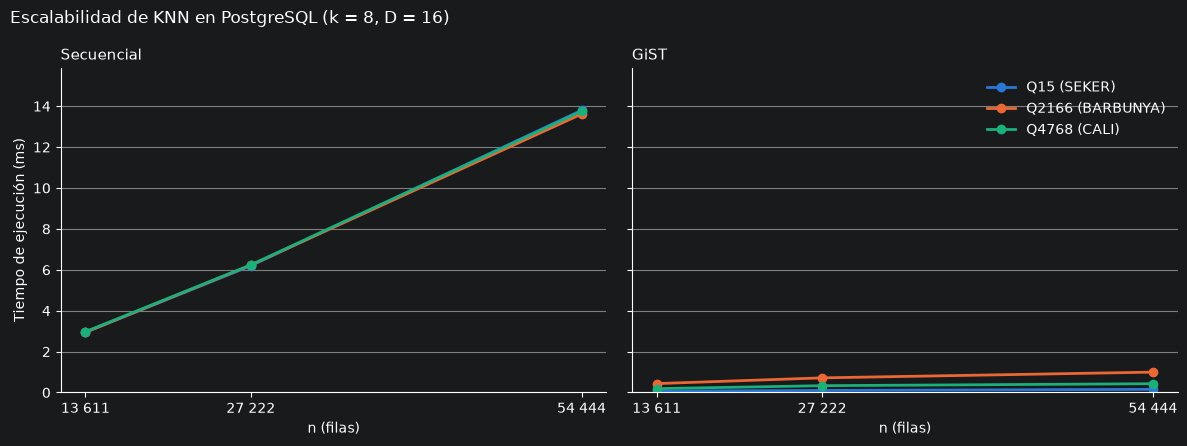

In [52]:
plot_tiempos(rep_tabla, "n (filas)", f"Escalabilidad de KNN en PostgreSQL (k = {REP_K}, D = 16)", "results/p3_escalabilidad.png")

### Pregunta de análisis: ¿Qué tan eficiente es el índice GiST (R-Tree) con vectores de dimensión 16?

Con $D = 16$ el índice es muy eficiente en esta colección:

- **Frente a la búsqueda secuencial.** Con $n = 13\,611$, GiST resuelve KNN entre 5 y 50 veces más rápido (0.05–0.5 ms frente a ~2.3 ms). La secuencial cuesta lo mismo para cualquier consulta y cualquier $k$, porque siempre lee las $n$ filas: $O(n \cdot D)$. GiST solo abre los nodos necesarios, así que su costo crece con $k$ y depende de la densidad de la zona de la consulta: $Q_{15}$ (SEKER, zona densa) es la más rápida y $Q_{2166}$ (BARBUNYA, zona dispersa) la más lenta.
- **Escalabilidad.** Al duplicar la colección, la secuencial duplica su tiempo. GiST crece mucho más lento: con ×4 su tiempo se multiplica por ~2. El speedup aumenta con $n$: el índice rinde más cuanto más grande es la colección, porque bajar por el árbol cuesta del orden de su altura, $O(\log n)$, más el trabajo de extraer los $k$ vecinos.
- **Limitación de la replicación.** `INSERT INTO ... SELECT` crea copias exactas: con ×4, los 8 vecinos de una consulta son 4 copias de sí misma (a distancia 0) y 4 copias de su vecino más cercano. Una colección real del mismo tamaño no tendría esa concentración de puntos idénticos, así que la replicación mide bien el crecimiento de la búsqueda secuencial, pero no reproduce exactamente el comportamiento de GiST con datos nuevos.

## P3: Dimensionalidad

Se repite la comparación con datos sintéticos: vectores con coordenadas aleatorias uniformes en $[0, 1]$, en una tabla `vectors` con una columna sin índice (`vector_lineal`) y otra con GiST (`vector_gist`). Para cada dimensión se crea la tabla con $n = 100\,000$ vectores, se construye el índice y se mide KNN con $k = 8$ para 5 puntos de consulta aleatorios, por rondas y con la mediana, igual que antes.

La extensión `cube` admite como máximo 100 dimensiones. Por eso el experimento llega hasta $D = 100$ en lugar de 128.

Además del tiempo se registran las páginas leídas (`BUFFERS`) para ver qué fracción del índice recorre GiST.

In [53]:
SYN_N = 100_000
SYN_DIMS = [2, 4, 8, 16, 32, 64, 100]
SYN_K = 8
SYN_QUERIES = 5
SYN_COLUMNS = {"vector_lineal": "Secuencial", "vector_gist": "GiST"}

rng = np.random.default_rng(42)
rows, index_pages = [], {}
conn = connect_db()
conn.autocommit = True
with conn.cursor() as cur:
    for D in SYN_DIMS:
        cur.execute(f"""
            SELECT setseed(0.42);
            DROP TABLE IF EXISTS vectors;
            CREATE TABLE vectors (id serial, vector_lineal cube, vector_gist cube);
            INSERT INTO vectors(vector_lineal, vector_gist)
            SELECT cube(v), cube(v)
            FROM (
                SELECT ARRAY_AGG(random()) AS v
                FROM generate_series(1, {SYN_N}) r
                CROSS JOIN LATERAL generate_series(1, {D})
                GROUP BY r
            ) t;
            CREATE INDEX idx_vectorind ON vectors USING gist(vector_gist);
            ANALYZE vectors;
        """)
        cur.execute("SELECT pg_relation_size('idx_vectorind') / current_setting('block_size')::int;")
        index_pages[D] = cur.fetchone()[0]

        queries = rng.random((SYN_QUERIES, D)).tolist()
        for _ in range(N_REPS):
            for q in queries:
                for column, metodo in SYN_COLUMNS.items():
                    plan = knn_plan(cur, column, q, SYN_K, table="vectors")
                    rows.append({"D": D, "método": metodo, "ms": plan["Execution Time"],
                                 "páginas": plan["Plan"]["Shared Hit Blocks"] + plan["Plan"]["Shared Read Blocks"]})
conn.close()

syn = pd.DataFrame(rows).groupby(["D", "método"])[["ms", "páginas"]].median().unstack("método")
dim_tabla = pd.DataFrame({
    "Secuencial (ms)": syn[("ms", "Secuencial")],
    "GiST (ms)": syn[("ms", "GiST")],
    "Speedup": syn[("ms", "Secuencial")] / syn[("ms", "GiST")],
    "Páginas del índice": pd.Series(index_pages),
    "% del índice leído por GiST": (syn[("páginas", "GiST")] / pd.Series(index_pages) * 100).clip(upper=100),
})
dim_tabla.to_csv("results/p3_dimensionalidad.csv")
display(dim_tabla.round(2))

,Secuencial (ms),GiST (ms),Speedup,Páginas del índice,% del índice leído por GiST
2,14.67,0.05,274.15,839,1.43
4,15.16,0.23,65.36,1227,3.75
8,18.35,4.05,4.53,1961,33.91
16,25.41,19.67,1.29,3916,94.69
32,36.55,34.32,1.06,7940,100.00
64,59.53,55.50,1.07,12500,100.00
100,86.76,118.49,0.73,21219,100.00


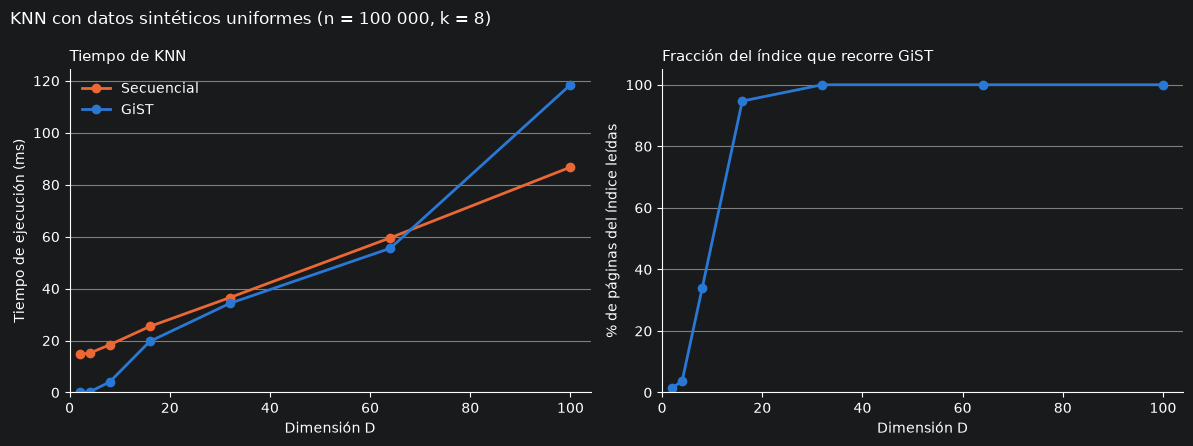

In [54]:
fig, (ax_t, ax_p) = plt.subplots(1, 2, figsize=(12, 4.5))

for metodo, color in [("Secuencial", "#eb6834"), ("GiST", "#2a78d6")]:
    ax_t.plot(SYN_DIMS, dim_tabla[f"{metodo} (ms)"], color=color, linewidth=2, marker="o", markersize=6, label=metodo)
ax_t.set_title("Tiempo de KNN", loc="left", fontsize=11)
ax_t.set_ylabel("Tiempo de ejecución (ms)")
ax_t.set_ylim(bottom=0)
ax_t.legend(frameon=False)

ax_p.plot(SYN_DIMS, dim_tabla["% del índice leído por GiST"], color="#2a78d6", linewidth=2, marker="o", markersize=6)
ax_p.set_title("Fracción del índice que recorre GiST", loc="left", fontsize=11)
ax_p.set_ylabel("% de páginas del índice leídas")
ax_p.set_ylim(0, 105)

for ax in (ax_t, ax_p):
    ax.set_xticks(range(0, 101, 20))
    ax.set_xlim(0, 104)
    ax.set_xlabel("Dimensión D")
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

n_txt = f"{SYN_N:,}".replace(",", " ")
fig.suptitle(f"KNN con datos sintéticos uniformes (n = {n_txt}, k = {SYN_K})", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig("results/p3_dimensionalidad.png", dpi=150)
plt.show()

### Pregunta de análisis: ¿Hasta qué dimensión $D$ conviene usar GiST para KNN vs. búsqueda lineal?

Con estos datos sintéticos, GiST conviene hasta $D \approx 8$.

En el gráfico de la izquierda, la búsqueda secuencial crece en línea recta con $D$: siempre lee todas las filas, y cada distancia cuesta más mientras más dimensiones hay. GiST empieza en casi 0 ms pero sube muy rápido. En $D = 8$ todavía es varias veces más rápido; en $D = 16$ ya casi alcanza a la secuencial; entre $D = 32$ y $64$ van prácticamente juntos, y en $D = 100$ GiST es más lento.

El gráfico de la derecha explica por qué: muestra qué parte del índice tiene que leer GiST. Con $D \le 4$ lee menos del 5 %, en $D = 8$ cerca de un 30 % y desde $D = 16$ prácticamente todo. Si el índice se lee entero ya no ahorra nada: hace el mismo trabajo que la secuencial más el costo de recorrer el árbol. En $D = 100$, además, el índice ocupa más páginas de las que caben en la memoria caché de PostgreSQL (128 MB). En cada consulta GiST tiene que traer sus páginas desde fuera de la caché, saltando de una a otra según el recorrido del árbol, mientras que la búsqueda secuencial lee la tabla de corrido, de la primera página a la última, lo que es mucho más barato. Por eso pierde con más diferencia.

Estos datos son el peor caso para un índice: cada coordenada se genera con su propio `random()`, así que conocer una no dice nada de las demás. Cada dimensión aporta variación nueva, así que los puntos se reparten por todo el espacio, en todas las direcciones.

Los vectores de Dry Bean son distintos, porque varios de sus 16 atributos miden casi lo mismo. `Area`, `ConvexArea`, `Perimeter` y `EquivDiameter` describen el tamaño del grano: `Area` y `ConvexArea` son prácticamente idénticos (correlación de 0.9999), porque el área de un grano y la de su contorno convexo casi no difieren. De forma parecida, `AspectRatio`, `Compactness` y `ShapeFactor3` describen qué tan alargado es. Aunque el vector tenga 16 columnas, los granos se concentran a lo largo de pocas direcciones (tamaño, alargamiento y algunas más), y el índice se comporta como con datos de pocas dimensiones. Por eso con Dry Bean ($D = 16$) GiST fue entre 5 y 50 veces más rápido, mientras que con datos sintéticos de $D = 16$ apenas gana.

El límite $D \approx 8$ es entonces orientativo: lo que importa no es cuántas columnas tiene el vector, sino cuántas varían de forma independiente.